# In-situ HICCUPS loops → APA on sc-imputed matrices

Variant of `loop_25kb_diff.ipynb` that uses **in-situ HICCUPS loop calls** (depth-matched GM-sub + full IMR) as the loop universe, then applies the same ANOVA-based differential analysis on the **sc-imputed Q/E/T matrices** from `loop_majortype_25kb/`.

Loop sources:
- GM12878-sub: `gm_insitu_sub_hiccups_25kb_loops/merged_loops.bedpe` (6,254 loops)
- IMR90 full: `imr_insitu_hiccups_25kb_loops/merged_loops.bedpe` (9,222 loops)

Question: do loops called on the deep in-situ Hi-C show cell-type-specific signal in our 441-cell sc pseudobulks?


In [1]:
import os

# Set working directory"
os.chdir("/home/jmj7858/epifluidlab/sc_nomehic_cellline/hic")


In [2]:
import sys, cooler
print("python:", sys.executable)
print("cooler version:", cooler.__version__)
print("cooler path:", cooler.__file__)

python: /projects/b1198/epifluidlab/yoshii/software/conda/envs/hic_cooler/bin/python
cooler version: 0.10.4
cooler path: /projects/b1198/epifluidlab/yoshii/software/conda/envs/hic_cooler/lib/python3.10/site-packages/cooler/__init__.py


In [3]:
import os
import cooler
import pathlib
import numpy as np
import pandas as pd
from scipy.sparse import load_npz, save_npz, vstack, csr_matrix, triu
from scipy.stats import f, zscore, ranksums
from cooler.create import create_scool
from schicluster.cool.utilities import get_chrom_offsets
from multiprocessing import Pool
from concurrent.futures import ProcessPoolExecutor, as_completed

In [4]:
import cooler
import pandas as pd

# ----------------------------
# Your cell types (each inner list = one group)
# ----------------------------
ctgroup = [
    ["GM12878"],
    ["IMR90"],
]
group_name = "GM12878_IMR90_insitu_loops"   # just a label for outputs
group = group_name

# ----------------------------
# Paths (match your make_celltype_cool.py output)
# ----------------------------
# All data was copied off /scratch into this folder on 2026-07-15 so that scratch
# purges cannot destroy it. BASE is the only path to change if this folder moves.
BASE = "/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu"

indir = f"{BASE}/data/per_celltype/"
outdir = f"{BASE}/data/"   # parent — cell 6/7/8 write to {outdir}diff/{group}/
res = 25000

# ----------------------------
# Chrom sizes + bins
# ----------------------------
chrom_size_path = "/gpfs/projects/b1198/epifluidlab/yoshii/reference/hg38/autosomes.chrom.sizes"
chrom_sizes = cooler.read_chromsizes(chrom_size_path, all_names=True)

bins_df = cooler.binnify(chrom_sizes, res)

# if get_chrom_offsets is defined later in the notebook, keep as-is:
chrom_offset = get_chrom_offsets(bins_df)


In [5]:
bkl = pd.read_csv(f'/gpfs/projects/b1198/epifluidlab/yoshii/reference/hg38/hg38-blacklist.v2.bed', sep='\t', header=None, index_col=None)

In [6]:
def compute_anova(c, matrix):
    # c, matrix = args
    ngene = int(chrom_sizes.loc[c] // res) + 1
    bkl_tmp = bkl.loc[(bkl[0]==c), [1,2]].values // res
    cov = np.zeros(ngene)
    for xx,yy in bkl_tmp:
        cov[xx-7:yy+7] = 1
    tot, last = 0, 0
    Esum, E2sum, Elast, E2last, ss_intra = [csr_matrix((ngene, ngene)) for i in range(5)]
    for ctlist in ctgroup:
        for ct in ctlist:
            cool_e = cooler.Cooler(f'{indir}/{ct}/{ct}/{ct}.{matrix}.cool')
            E = triu(cool_e.matrix(balance=False, sparse=True).fetch(c))
            cool_e2 = cooler.Cooler(f'{indir}/{ct}/{ct}/{ct}.{matrix}2.cool')
            E2 = triu(cool_e2.matrix(balance=False, sparse=True).fetch(c))
            n = cool_e.info['group_n_cells']
            Esum += E * n
            E2sum += E2 * n
            tot += n
            # print(c, ct)
        Egroup = Esum - Elast
        E2group = E2sum - E2last
        Egroup.data = Egroup.data ** 2 / (tot - last)
        ss_intra += (E2group - Egroup)
        Elast = Esum.copy()
        E2last = E2sum.copy()
        last = tot
    Esum.data = Esum.data ** 2 / tot
    ss_total = E2sum - Esum
    ss_intra.data = 1 / ss_intra.data
    ss_total = ss_total.multiply(ss_intra)
    # print(c, ss_total.data.min(), ss_intra.data.min())

    ss_total.data = (ss_total.data - 1) * (tot - len(ctgroup)) / (len(ctgroup) - 1)
    ss_total = ss_total.tocoo()
    bklfilter = np.logical_and(cov[ss_total.row]==0, cov[ss_total.col]==0)
    distfilter = np.logical_and((ss_total.col-ss_total.row)>5, (ss_total.col-ss_total.row)<500)
    idxfilter = np.logical_and(bklfilter, distfilter)
    # print(idxfilter.sum(), len(idxfilter))
    ss_total = csr_matrix((ss_total.data[idxfilter], (ss_total.row[idxfilter], ss_total.col[idxfilter])), (ngene, ngene))
    save_npz(f'{outdir}diff/{group}/majortype_{matrix}pv_{c}.npz', ss_total)

    return [c, matrix, tot]

In [7]:
cpu = 10
from pathlib import Path

Path(outdir).joinpath("diff", group).mkdir(parents=True, exist_ok=True)

with ProcessPoolExecutor(cpu) as executor:
    futures = []
    for x in chrom_sizes.index:
        for y in ['Q', 'E', 'T']:
            future = executor.submit(
                compute_anova,
                c=x,
                matrix=y,
            )
            futures.append(future)

    # result = []
    for future in as_completed(futures):
        # result.append(future.result())
        # c1, c2 = result[-1][0], result[-1][1]
        tmp = future.result()
        print(f'{tmp[0]} {tmp[1]} finished')


chr2 E finished
chr1 E finished
chr2 T finished
chr1 T finished
chr3 T finished
chr3 Q finished
chr3 E finished
chr4 Q finished
chr1 Q finished
chr2 Q finished
chr5 T finished
chr5 E finished
chr7 Q finished
chr5 Q finished
chr4 E finished
chr6 Q finished
chr6 T finished
chr4 T finished
chr6 E finished
chr7 E finished
chr10 Q finished
chr9 E finished
chr9 Q finished
chr9 T finished
chr8 T finished
chr8 Q finished
chr8 E finished
chr7 T finished
chr11 T finished
chr12 T finished
chr10 T finished
chr13 E finished
chr12 E finished
chr11 E finished
chr13 Q finished
chr12 Q finished
chr11 Q finished
chr10 E finished
chr15 Q finished
chr14 E finished
chr16 E finished
chr15 E finished
chr15 T finished
chr14 T finished
chr13 T finished
chr16 Q finished
chr14 Q finished
chr19 Q finished
chr18 Q finished
chr17 Q finished
chr18 T finished
chr17 T finished
chr16 T finished
chr19 E finished
chr18 E finished
chr17 E finished
chr22 Q finished
chr21 Q finished
chr19 T finished
chr20 Q finished
chr22 E

In [8]:
def chrom_iterator(input_dir, chrom_order, chrom_offset):
    for chrom in chrom_order:
        output_path = f'{input_dir}_{chrom}.npz'
        if not pathlib.Path(output_path).exists():
            continue
        chunk_size = 5000000
        data = load_npz(output_path).tocoo()
        df = pd.DataFrame({'bin1_id': data.row, 'bin2_id': data.col, 'count': data.data})
        df = df[df['bin1_id'] <= df['bin2_id']]
        for i, chunk_start in enumerate(range(0, df.shape[0], chunk_size)):
            chunk = df.iloc[chunk_start:chunk_start + chunk_size]
            chunk.iloc[:, :2] += chrom_offset[chrom]
            yield chunk

In [9]:
for matrix in ['Q', 'E', 'T']:
    output_path = f'{outdir}diff/{group}/majortype_{matrix}pv'
    cooler.create_cooler(cool_uri=f'{output_path}.cool',
                         bins=bins_df,
                         pixels=chrom_iterator(input_dir=output_path,
                                               chrom_order=chrom_sizes.index,
                                               chrom_offset=chrom_offset
                                              ),
                         ordered=True,
                         dtypes={'count': np.float32})

In [10]:
os.system(f'rm {outdir}diff/{group}/majortype_*pv_c*.npz')

0

In [11]:
import cooler
import numpy as np
import pandas as pd
from scipy.sparse import triu
from scipy.stats import pearsonr, zscore, norm
from multiprocessing import Pool
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib import cm as cm
import seaborn as sns

mpl.style.use('default')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']


In [12]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import cooler

# ============================================================
# In-situ loop variant of loop_25kb_diff.ipynb
#
# Loop list source : ENCODE in-situ Hi-C HICCUPS bedpes (depth-matched GM-sub + IMR-full)
# Q/E/T matrices   : sc-imputed per cell type (from snakemake/loop_majortype_25kb/step05)
# APA target       : same sc-imputed Q matrices (cells 50+)
#
# Question this notebook answers: do loops called on the deep in-situ Hi-C show
# differential SC-level signal in our 441-cell pseudobulks?
# ============================================================

celltypes = ["GM12878", "IMR90"]
ctgroup   = [[ct] for ct in celltypes]
leg       = pd.Index(celltypes)
leg2name  = {ct: ct for ct in celltypes}
legname   = leg.map(leg2name)

res = 25000

# All data was copied off /scratch into this folder on 2026-07-15 so that scratch
# purges cannot destroy it. BASE is the only path to change if this folder moves.
BASE = "/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu"

# sc-imputed inputs (Q/E/T cool), copied from loop_majortype_25kb/per_celltype
indir = f"{BASE}/data/per_celltype"
group_name = "GM12878_IMR90_insitu_loops"
outdir = f"{BASE}/data/diff/{group_name}/"   # = parent + diff/{group_name}/ — same dir cell 8 wrote .cool files to
Path(outdir).mkdir(parents=True, exist_ok=True)

chrom_size_path = "/gpfs/projects/b1198/epifluidlab/yoshii/reference/hg38/autosomes.chrom.sizes"
chrom_sizes = cooler.read_chromsizes(chrom_size_path, all_names=True)
if not any(str(c).startswith("chr") for c in chrom_sizes.index):
    chrom_sizes.index = ["chr" + str(c) for c in chrom_sizes.index]
bins_df = cooler.binnify(chrom_sizes, res)

# ============================================================
# Load in-situ HICCUPS loop bedpes (depth-matched GM-sub + IMR-full)
# ============================================================
INSITU_BEDPE = {
    "GM12878": f"{BASE}/data/loops/gm_insitu_sub_hiccups_25kb_loops/merged_loops.bedpe",
    "IMR90":   f"{BASE}/data/loops/imr_insitu_hiccups_25kb_loops/merged_loops.bedpe",
}

loopall_list = []
for ct in leg:
    path = INSITU_BEDPE[ct]
    # HICCUPS bedpes start with '#' comment lines for header
    df = pd.read_csv(path, sep="\t", header=None, comment="#", low_memory=False)
    # ensure chrom strings start with 'chr'
    df[0] = df[0].astype(str)
    df[3] = df[3].astype(str)
    df[0] = df[0].where(df[0].str.startswith("chr"), "chr" + df[0])
    df[3] = df[3].where(df[3].str.startswith("chr"), "chr" + df[3])
    print(f"  {ct}: {len(df)} in-situ HICCUPS loops")
    loopall_list.append(df)

loopall = pd.concat(loopall_list, axis=0, ignore_index=True)

# Keep only the 6 BEDPE coord columns (HICCUPS bedpes have many extra: score, color, etc.)
loopall = loopall.iloc[:, :6]

# Dedupe by (chrom, start1, start2) — same as original notebook
loopall = (
    loopall.drop_duplicates(subset=[0, 1, 4])
           .sort_values([0, 1, 4])
)

# Reorder rows to chrom_sizes order
loopall = pd.concat([loopall[loopall[0] == c] for c in chrom_sizes.index], axis=0, ignore_index=True)

print(f"\nunion of in-situ loops (dedupe by chr+start1+start2): {len(loopall)}")
loopall.head()


  GM12878: 6254 in-situ HICCUPS loops
  IMR90: 9222 in-situ HICCUPS loops

union of in-situ loops (dedupe by chr+start1+start2): 12101


,0,1,2,3,4,5
0,chr1,1925000,1950000,chr1,2025000,2050000
1,chr1,1950000,1975000,chr1,2150000,2175000
2,chr1,1950000,1975000,chr1,2350000,2375000
3,chr1,2175000,2200000,chr1,2375000,2400000
4,chr1,2175000,2200000,chr1,2525000,2550000


In [13]:
loopall.to_csv(f'{outdir}merged_loop.bedpe', sep='\t', index=False, header=False)
loopall.to_hdf(f'{outdir}merged_loop.hdf', key='data')

In [14]:
for c in chrom_sizes.index[:-1]:
    loopfilter = (loopall[0]==c)
    looptmp = loopall.loc[loopfilter, [1,4]].values // res
    for matrix in ['Q', 'E', 'T']:
        cool = cooler.Cooler(f'{outdir}majortype_{matrix}pv.cool')
        pv = triu(cool.matrix(balance=False, sparse=True).fetch(c)).tocsr()
        loopall.loc[loopfilter, f'{matrix}anova'] = pv[(looptmp[:,0], looptmp[:,1])].A1
    print(c)

chr1
chr2
chr3
chr4
chr5
chr6
chr7
chr8
chr9
chr10
chr11
chr12
chr13
chr14
chr15
chr16
chr17
chr18
chr19
chr20
chr21


In [15]:
loopall[~loopall['Qanova'].isna()].to_hdf(f'{outdir}merged_loop.hdf', key='data')

/tmp/ipykernel_21709/1444337755.py:1: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed-integer,key->axis0] [items->None]

  loopall[~loopall['Qanova'].isna()].to_hdf(f'{outdir}merged_loop.hdf', key='data')
/tmp/ipykernel_21709/1444337755.py:1: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->integer,key->block1_items] [items->None]

  loopall[~loopall['Qanova'].isna()].to_hdf(f'{outdir}merged_loop.hdf', key='data')
/tmp/ipykernel_21709/1444337755.py:1: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->integer,key->block2_items] [items->None]

  loopall[~loopall['Qanova'].isna()].to_hdf(f'{outdir}merged_loop.hdf', key='data')


In [16]:
loopall

,0,1,2,3,4,5,Qanova,Eanova,Tanova
0,chr1,1925000,1950000,chr1,2025000,2050000,0.000000,0.000000,0.000000
1,chr1,1950000,1975000,chr1,2150000,2175000,0.117976,0.024920,0.000406
2,chr1,1950000,1975000,chr1,2350000,2375000,0.347858,0.909346,1.210174
3,chr1,2175000,2200000,chr1,2375000,2400000,1.518632,1.830539,1.553588
4,chr1,2175000,2200000,chr1,2525000,2550000,0.008940,0.222688,0.200752
...,...,...,...,...,...,...,...,...,...
12096,chr22,49750000,49775000,chr22,50025000,50050000,NaN,NaN,NaN
12097,chr22,49800000,49825000,chr22,49900000,49925000,NaN,NaN,NaN
12098,chr22,49800000,49825000,chr22,50200000,50225000,NaN,NaN,NaN
12099,chr22,49925000,49950000,chr22,50025000,50050000,NaN,NaN,NaN


In [17]:
loopall = pd.read_hdf(f'{outdir}merged_loop.hdf', key='data')
loopall

,0,1,2,3,4,5,Qanova,Eanova,Tanova
0,chr1,1925000,1950000,chr1,2025000,2050000,0.000000,0.000000,0.000000
1,chr1,1950000,1975000,chr1,2150000,2175000,0.117976,0.024920,0.000406
2,chr1,1950000,1975000,chr1,2350000,2375000,0.347858,0.909346,1.210174
3,chr1,2175000,2200000,chr1,2375000,2400000,1.518632,1.830539,1.553588
4,chr1,2175000,2200000,chr1,2525000,2550000,0.008940,0.222688,0.200752
...,...,...,...,...,...,...,...,...,...
11933,chr21,45125000,45150000,chr21,45800000,45825000,3.144411,5.818660,3.029803
11934,chr21,45275000,45300000,chr21,45425000,45450000,0.718228,0.229171,0.085188
11935,chr21,45275000,45300000,chr21,45800000,45825000,0.077451,0.304641,0.385769
11936,chr21,45550000,45575000,chr21,45800000,45825000,1.313976,2.251320,1.296072


In [18]:
def load_Q(ct, m):
    tmp = []
    cool_file = cooler.Cooler(f'{indir}/{ct}/{ct}/{ct}.{m}.cool').matrix(balance=False, sparse=True)
    for c in chrom_sizes.index[:-1]:
        mat = cool_file.fetch(c).tocsr()
        tmp.append(mat[(loopall.loc[loopall[0]==c, 1].values // res, loopall.loc[loopall[0]==c, 4].values // res)].A1)
        # print(ct, c)
    return [ct, np.concatenate(tmp)]

In [19]:
cpu = 5
with ProcessPoolExecutor(cpu) as executor:
    futures = []
    for xx in leg:
        future = executor.submit(
            load_Q,
            ct=xx,
            m='Q'
        )
        futures.append(future)

    loopq = []
    for future in as_completed(futures):
        tmp = future.result()
        loopq.append(pd.DataFrame(tmp[1], columns=[tmp[0]]))
        print(f'{tmp[0]} finished')

IMR90 finished
GM12878 finished


In [20]:
loopq = pd.concat(loopq, axis=1)
loopq = loopq[leg]

In [21]:
loopq.to_hdf(f'{outdir}loop_Q.hdf', key='data')

In [22]:
loopq

,GM12878,IMR90
0,0.015136,0.019407
1,0.005516,0.006303
2,0.002276,0.003146
3,0.008385,0.005189
4,0.003132,0.003314
...,...,...
11933,0.003311,0.000938
11934,0.008411,0.006119
11935,0.002670,0.003097
11936,0.005005,0.007896


In [23]:
cpu = 5
with ProcessPoolExecutor(cpu) as executor:
    futures = []
    for xx in leg:
        future = executor.submit(
            load_Q,
            ct=xx,
            m='T'
        )
        futures.append(future)

    loopt = []
    for future in as_completed(futures):
        tmp = future.result()
        loopt.append(pd.DataFrame(tmp[1], columns=[tmp[0]]))
        print(f'{tmp[0]} finished')

GM12878 finished
IMR90 finished


In [24]:
loopt = pd.concat(loopt, axis=1)
loopt = loopt[leg]  

In [25]:
loopt.to_hdf(f'{outdir}loop_T.hdf', key='data')

In [26]:
loopq = pd.read_hdf(f'{outdir}loop_Q.hdf', key='data')
loopt = pd.read_hdf(f'{outdir}loop_T.hdf', key='data')

In [27]:
loopq

,GM12878,IMR90
0,0.015136,0.019407
1,0.005516,0.006303
2,0.002276,0.003146
3,0.008385,0.005189
4,0.003132,0.003314
...,...,...
11933,0.003311,0.000938
11934,0.008411,0.006119
11935,0.002670,0.003097
11936,0.005005,0.007896


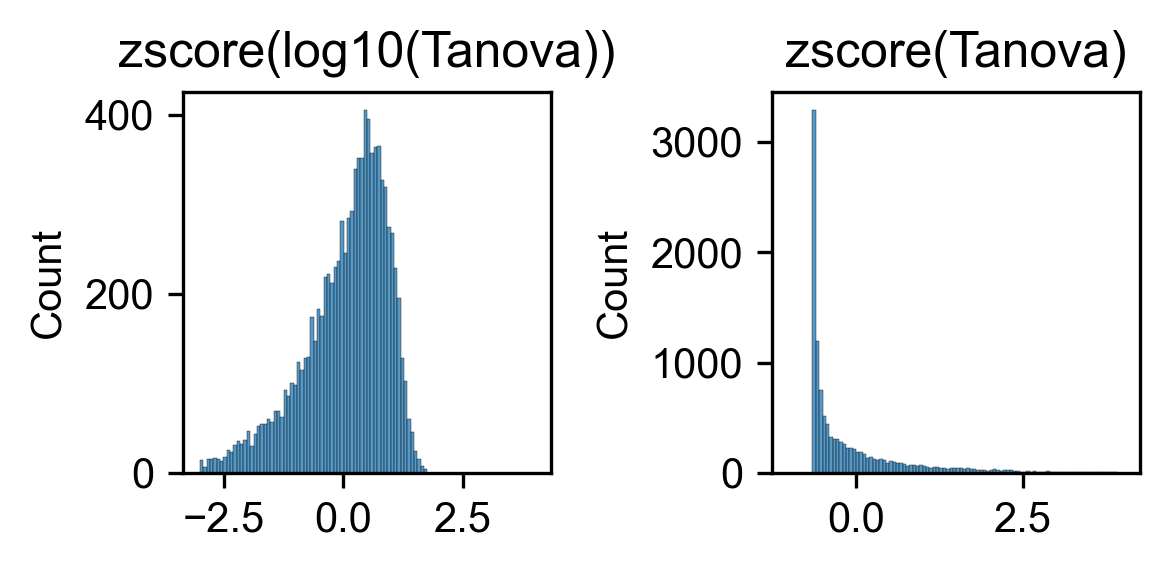

In [28]:
t = loopall['Tanova'].to_numpy()

# remove NaN and non-positive values (needed for log10)
t_log = t[np.isfinite(t) & (t > 0)]
t_raw = t[np.isfinite(t)]

# ---- plot ----
fig, axes = plt.subplots(1, 2, figsize=(4, 2), dpi=300)

sns.histplot(
    zscore(np.log10(t_log)),
    bins=100, binrange=(-3, 4),
    ax=axes[0]
)
axes[0].set_title("zscore(log10(Tanova))")

sns.histplot(
    zscore(t_raw),
    bins=100, binrange=(-1, 4),
    ax=axes[1]
)
axes[1].set_title("zscore(Tanova)")

plt.tight_layout()


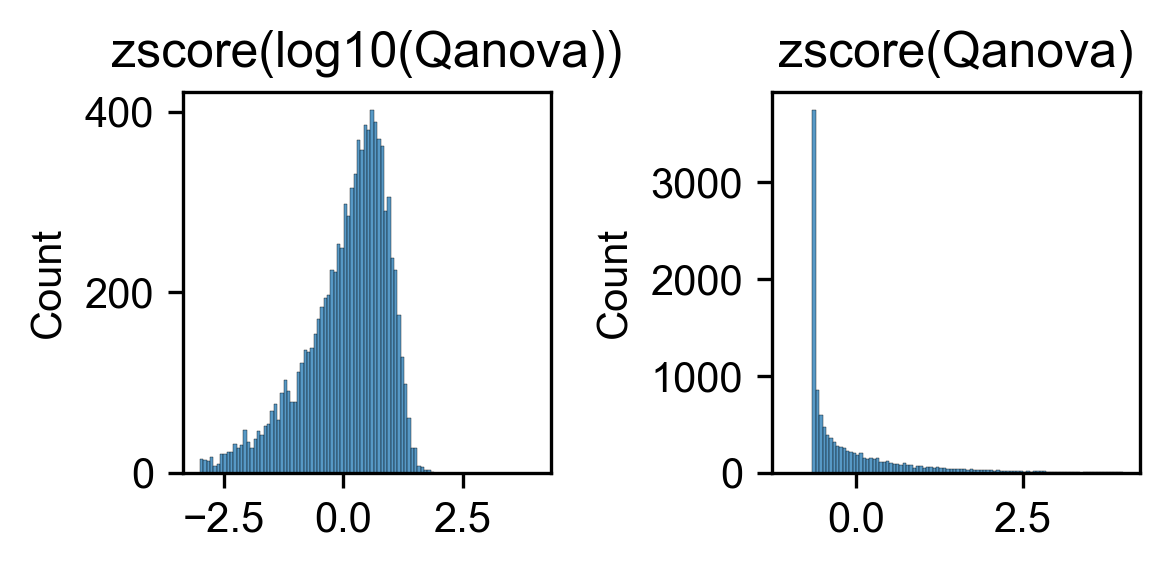

In [29]:
t = loopall['Qanova'].to_numpy()

# remove NaN and non-positive values (needed for log10)
t_log = t[np.isfinite(t) & (t > 0)]
t_raw = t[np.isfinite(t)]

# ---- plot ----
fig, axes = plt.subplots(1, 2, figsize=(4, 2), dpi=300)

sns.histplot(
    zscore(np.log10(t_log)),
    bins=100, binrange=(-3, 4),
    ax=axes[0]
)
axes[0].set_title("zscore(log10(Qanova))")

sns.histplot(
    zscore(t_raw),
    bins=100, binrange=(-1, 4),
    ax=axes[1]
)
axes[1].set_title("zscore(Qanova)")

plt.tight_layout()


In [30]:
thres1 = norm.isf(0.025)
thres2 = norm.isf(0.15)
print(thres1, thres2)

1.9599639845400545 1.0364333894937898


In [31]:
selb = ((zscore(loopall[~loopall['Qanova'].isna()]['Qanova'])>thres2) & (zscore(loopall[~loopall['Qanova'].isna()]['Tanova'])>thres2))

In [32]:
tmpq = loopq.loc[selb].values
# tmpq = zscore(tmpq, axis=1)

In [33]:
loopq.loc[selb].values

array([[7.2409643e-04, 4.9724667e-03],
       [1.2103030e-03, 5.1993276e-05],
       [6.1993543e-03, 1.7095309e-02],
       ...,
       [7.8744283e-03, 3.2830667e-03],
       [4.0584183e-04, 2.6655463e-03],
       [3.3113137e-03, 9.3811349e-04]], shape=(754, 2), dtype=float32)

In [34]:
tmpt = loopt.loc[selb].values
# tmpt = zscore(tmpt, axis=1)

In [35]:
len(tmpt)

754

In [36]:
np.random.seed(0)
sel = np.random.choice(np.arange(len(tmpq)), 754, False)

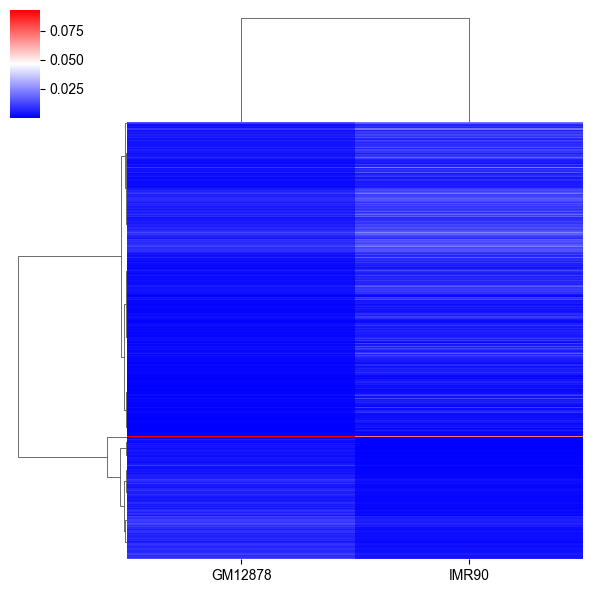

In [37]:
cg = sns.clustermap(tmpq[sel], cmap='bwr', metric='cosine', xticklabels=leg, yticklabels=[], figsize=(6,6))

In [38]:
rorder = cg.dendrogram_row.reordered_ind.copy()
corder = cg.dendrogram_col.reordered_ind.copy()

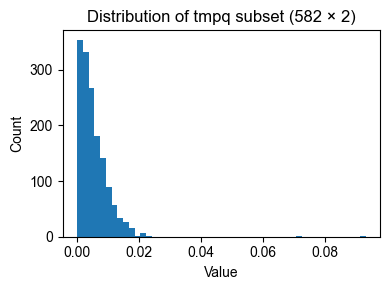

In [39]:
import numpy as np
import matplotlib.pyplot as plt

X = tmpq[np.ix_(sel[rorder], corder)]  # shape (582, 2)

vals = X.ravel()

plt.figure(figsize=(4, 3))
plt.hist(vals, bins=50)
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Distribution of tmpq subset (582 × 2)")
plt.tight_layout()
plt.show()


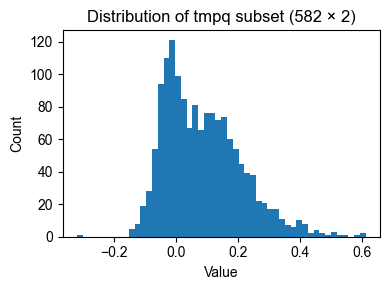

In [40]:
import numpy as np
import matplotlib.pyplot as plt

X = tmpt[np.ix_(sel[rorder], corder)]  # shape (582, 2)

vals = X.ravel()

plt.figure(figsize=(4, 3))
plt.hist(vals, bins=50)
plt.xlabel("Value")
plt.ylabel("Count")
plt.title("Distribution of tmpq subset (582 × 2)")
plt.tight_layout()
plt.show()


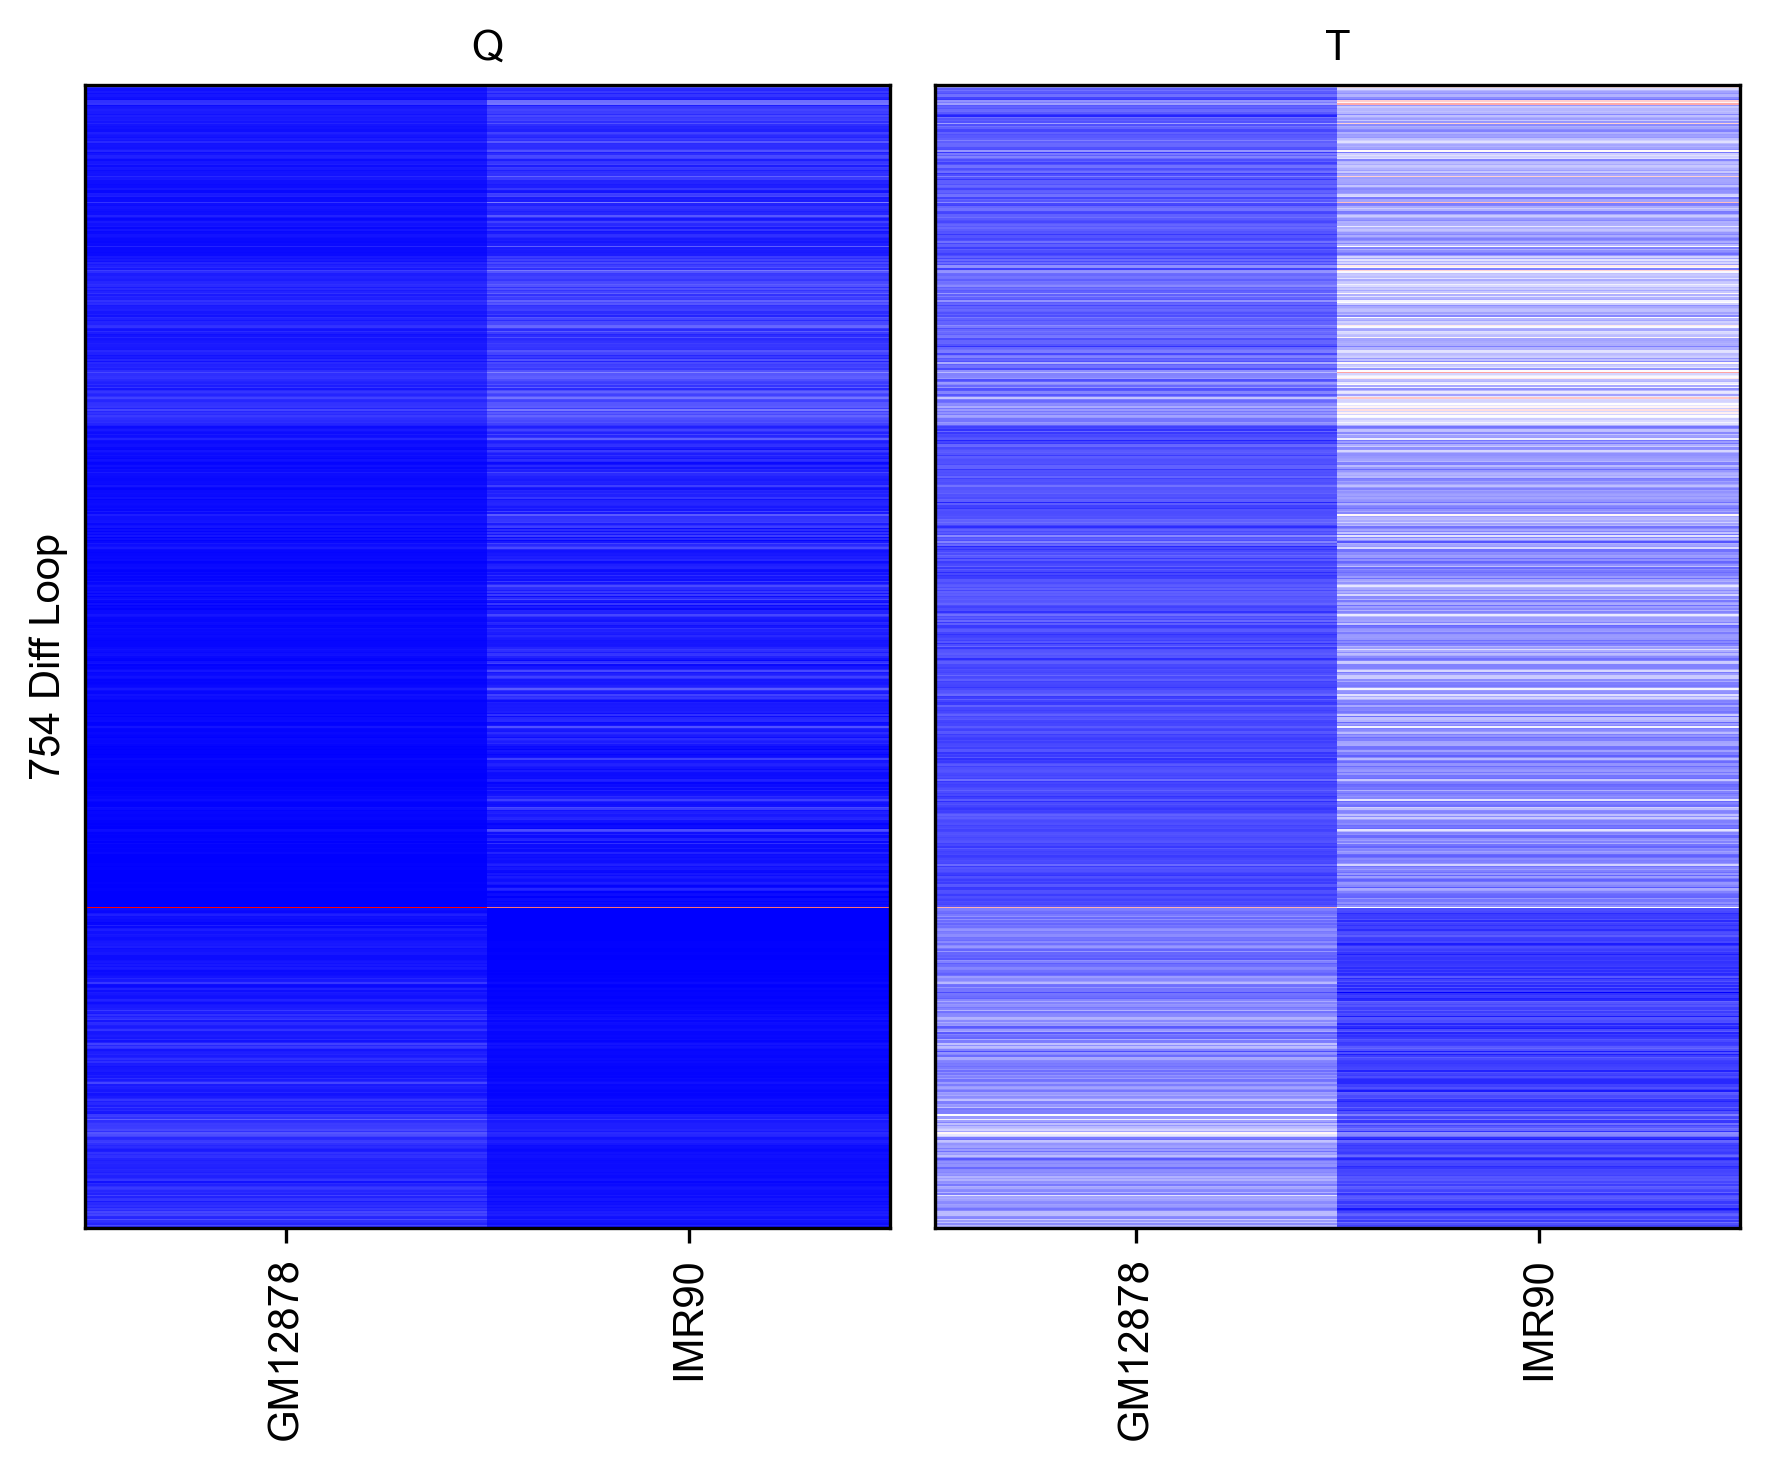

In [41]:
fig, axes = plt.subplots(1, 2, sharey='all', figsize=(6, 5), dpi=300)

ax = axes[0]
ax.imshow(tmpq[np.ix_(sel[rorder], corder)], cmap='bwr', aspect='auto', interpolation='none')
ax.set_title('Q', fontsize=10)
# sns.despine(ax=ax, left=True, bottom=True)
ax.set_xticks(np.arange(len(leg)))
ax.set_xticklabels(legname[corder], rotation=90)
ax.set_yticks([])
ax.set_ylabel(f'{tmpq.shape[0]} Diff Loop')

ax = axes[1]
ax.imshow(tmpt[np.ix_(sel[rorder], corder)], cmap='bwr', aspect='auto', vmin=-0.2, vmax=1, interpolation='none')
ax.set_title('T', fontsize=10)
# sns.despine(ax=ax, left=True, bottom=True)
ax.set_xticks(np.arange(len(leg)))
ax.set_xticklabels(legname[corder], rotation=90)

plt.tight_layout()

In [42]:
import cooler
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, zscore, norm
from multiprocessing import Pool
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib import cm as cm
import seaborn as sns

mpl.style.use('default')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']

In [43]:
loopq = pd.read_hdf(f'{outdir}loop_Q.hdf', key='data')
loopt = pd.read_hdf(f'{outdir}loop_T.hdf', key='data')
loopall = pd.read_hdf(f'{outdir}merged_loop.hdf', key='data')

In [44]:
thres1 = norm.isf(0.025)
thres2 = norm.isf(0.15)
print(thres1, thres2)

1.9599639845400545 1.0364333894937898


In [45]:
loopall[0].map(chrom_sizes)

0        248956422
1        248956422
2        248956422
3        248956422
4        248956422
           ...    
11933     46709983
11934     46709983
11935     46709983
11936     46709983
11937     46709983
Name: 0, Length: 11938, dtype: int64

In [46]:
selb = ((zscore(loopall['Qanova'])>thres2) & (zscore(loopall['Tanova'])>thres2))
distfilter = ((loopall[4]-loopall[1])>100000) & ((loopall[4]-loopall[1])<4950000) &  (loopall[1] >= (10*res)) & (loopall[4] < (loopall[0].map(chrom_sizes) - 10*res))
loopfilter = distfilter & selb
print(selb.sum(), loopfilter.sum())

754 753


In [47]:
loopall = loopall.loc[loopfilter]
loopq = loopq.loc[loopfilter]
loopt = loopt.loc[loopfilter]

In [48]:
loop_list = []
for ctlist in ctgroup:
    fc1 = loopq[ctlist].mean(axis=1) / loopq.loc[:, ~loopq.columns.isin(ctlist)].mean(axis=1)
    fc2 = loopt[ctlist].mean(axis=1) / loopt.loc[:, ~loopt.columns.isin(ctlist)].mean(axis=1)
    loop_list.append(loopall.loc[(fc1>1.2) & (fc2>1.5)])

In [49]:
[xx.shape[0] for xx in loop_list]

[39, 256]

In [50]:
apa_flank_bp = 200_000
apa_flank_bins = apa_flank_bp // res
apa_window_size = 2 * apa_flank_bins + 1

if apa_flank_bp % res != 0:
    raise ValueError("apa_flank_bp must be divisible by res")

def apa(ct):
    result = np.zeros((len(loop_list), apa_window_size, apa_window_size))
    counts = np.zeros(len(loop_list), dtype=np.int64)
    cool = cooler.Cooler(f'{indir}/{ct}/{ct}/{ct}.Q.cool')
    for c in np.random.permutation(chrom_sizes.index[:-1]):
        Q = cool.matrix(balance=False, sparse=True).fetch(c).toarray()
        decay = np.array([np.mean(np.diag(Q, k)) for k in range(dist)])
        E = np.zeros(Q.shape)
        row, col = np.diag_indices(E.shape[0])
        E[row, col] = 1
        for k in range(1, dist):
            dk = decay[k]
            if not np.isfinite(dk) or dk <= 0:
                continue
            E[row[:-k], col[k:]] = Q[row[:-k], col[k:]] / dk
        for j,loop in enumerate(loop_list):
            looptmp = loop.loc[(loop[0]==c), [1,4]].values // res
            for xx,yy in looptmp:
                tmp = E[(xx-apa_flank_bins):(xx+apa_flank_bins+1), (yy-apa_flank_bins):(yy+apa_flank_bins+1)]
                if tmp.shape != (apa_window_size, apa_window_size):
                    continue
                tmp = (tmp - tmp.min()) / (tmp.max() - tmp.min())
                result[j] += tmp
                counts[j] += 1
        n0 = np.sum(~np.isfinite(decay) | (decay <= 0))
        # print(ct, c, "decay<=0 or nonfinite:", n0, "of", len(decay))

        # print(ct, c, "E finite frac:", np.isfinite(E).mean(),
        #     "E inf count:", np.isinf(E).sum())
        
    for j,loop in enumerate(loop_list):
        if counts[j] > 0:
            result[j] /= counts[j]
        else:
            result[j][:] = np.nan
        
    return result


In [51]:
cpu = 5
dist = 505
result = np.zeros((len(leg), len(loop_list), apa_window_size, apa_window_size))
with ProcessPoolExecutor(cpu) as executor:
    futures = {}
    for i,ct in enumerate(leg):
        future = executor.submit(
            apa,
            ct=ct,
        )
        futures[future] = i

    for future in as_completed(futures):
        idx = futures[future]
        result[idx] = future.result()
        print(f'{leg[idx]} finished')


GM12878 finished
IMR90 finished


saved: /scratch/jmj7858/scnomehic/insitu_hic/loop_insitu_apa/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insitu_diffloops_v1.png


saved: /scratch/jmj7858/scnomehic/insitu_hic/loop_insitu_apa/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insitu_diffloops_v1.pdf


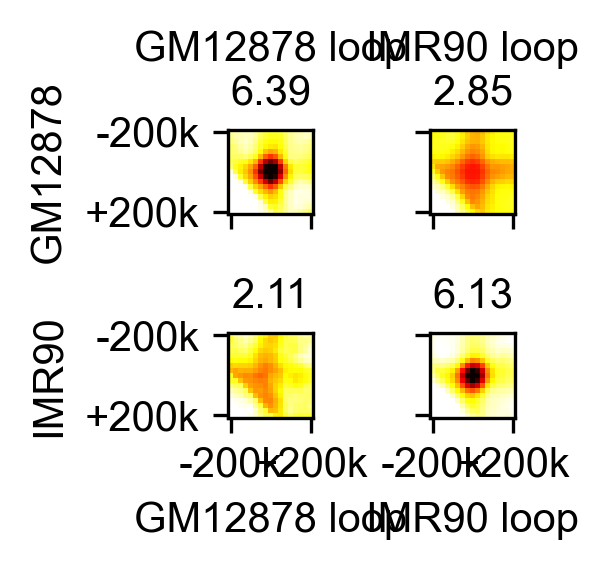

In [52]:
loop_labels = [' / '.join(map(str, ctlist)) + ' loop' for ctlist in ctgroup]

fig, axes = plt.subplots(len(leg), len(loop_list), figsize=(len(loop_list),len(leg)), 
                         sharex='all', sharey='all', dpi=300)
fig.subplots_adjust(wspace=0.5, hspace=1)
for i,ct in enumerate(leg):
    for j,loop in enumerate(loop_list):
        ax = axes[i, j]
        tmp = result[i, j]
        bg_width = max(1, min(5, apa_flank_bins))
        apa = np.around(tmp[apa_flank_bins, apa_flank_bins]/tmp[-bg_width:, :bg_width].mean(), decimals=2)
        ax.imshow(tmp, cmap='hot_r', vmax=0.8, vmin=0.2)
        if i==0:
            ax.set_title(f'{loop_labels[j]}\n{apa}', fontsize=10)
        else:
            ax.set_title(apa, fontsize=10)
            
for i,ct in enumerate(legname):
    axes[i,0].set_ylabel(ct)

for j, loop_label in enumerate(loop_labels):
    axes[-1,j].set_xlabel(loop_label)

edge_tick = apa_window_size - 1
edge_label = f'{apa_flank_bp // 1000}k'
ax.set_xticks([0, edge_tick])
ax.set_xticklabels([f'-{edge_label}', f'+{edge_label}'])
ax.set_yticks([0, edge_tick])
ax.set_yticklabels([f'-{edge_label}', f'+{edge_label}'])

plt.tight_layout()
import os
fig_outdir = os.path.join(outdir, 'figures')
os.makedirs(fig_outdir, exist_ok=True)
for ext in ('png', 'pdf'):
    fig_path = os.path.join(fig_outdir, f'APA_2xN_insitu_diffloops_v1.{ext}')
    fig.savefig(fig_path, dpi=300, bbox_inches='tight', transparent=(ext=='pdf'))
    print(f'saved: {fig_path}')


IMR90 finished
GM12878 finished


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insitu_diffloops.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insitu_diffloops.pdf


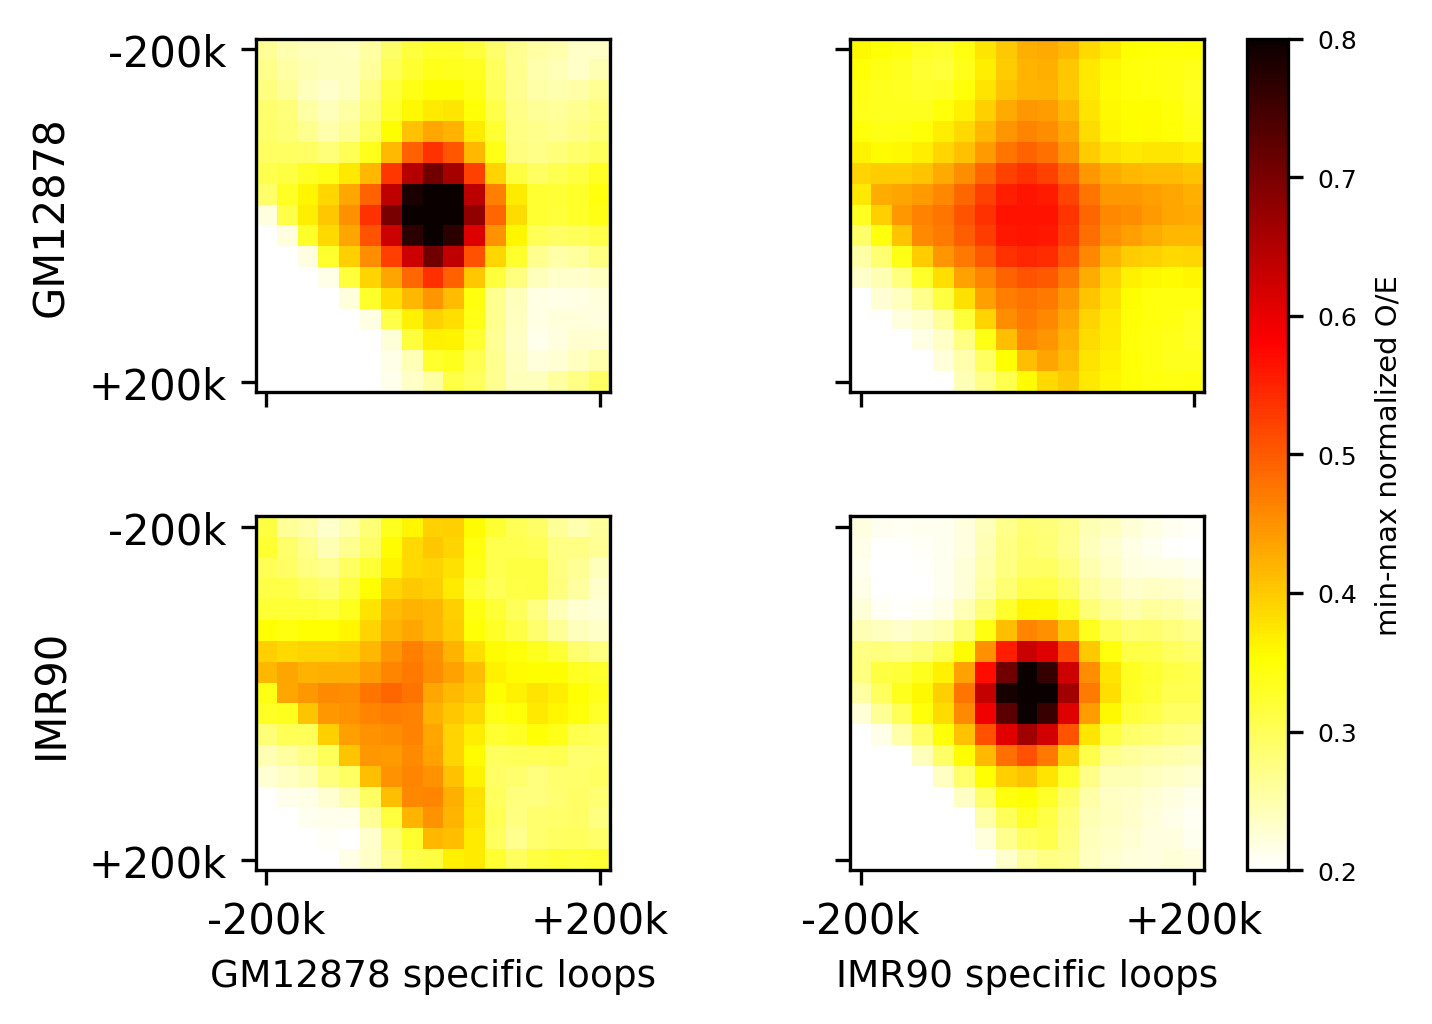

In [53]:
import numpy as np
import cooler

apa_flank_bp = 200_000
apa_flank_bins = apa_flank_bp // res
apa_window_size = 2 * apa_flank_bins + 1

if apa_flank_bp % res != 0:
    raise ValueError("apa_flank_bp must be divisible by res")

def apa(ct, indir, chrom_sizes, loop_list, res, dist=505, flank_bins=apa_flank_bins):
    n_sets = len(loop_list)
    window_size = 2 * flank_bins + 1

    # (1) for visualization (your original behavior, but safe)
    result_vis = np.zeros((n_sets, window_size, window_size), dtype=float)
    # (2) for scoring (no per-window minmax)
    result_raw = np.zeros((n_sets, window_size, window_size), dtype=float)

    counts = np.zeros(n_sets, dtype=np.int64)

    cool = cooler.Cooler(f"{indir}/{ct}/{ct}/{ct}.Q.cool")

    for c in np.random.permutation(chrom_sizes.index[:-1]):
        Q = cool.matrix(balance=False, sparse=True).fetch(c).toarray().astype(float)

        decay = np.empty(dist, dtype=float)
        for k in range(dist):
            d = np.diag(Q, k)
            decay[k] = np.nanmean(d) if d.size else np.nan

        E = np.zeros(Q.shape, dtype=float)
        row, col = np.diag_indices(E.shape[0])
        E[row, col] = 1.0

        for k in range(1, dist):
            dk = decay[k]
            if (not np.isfinite(dk)) or (dk <= 0):
                continue
            E[row[:-k], col[k:]] = Q[row[:-k], col[k:]] / dk

        for j, loop in enumerate(loop_list):
            looptmp = loop.loc[(loop[0] == c), [1, 4]].values // res
            if looptmp.size == 0:
                continue

            for xx, yy in looptmp:
                tmp = E[(xx - flank_bins):(xx + flank_bins + 1), (yy - flank_bins):(yy + flank_bins + 1)]
                if tmp.shape != (window_size, window_size):
                    continue

                tmp = tmp.astype(float, copy=True)
                tmp[~np.isfinite(tmp)] = np.nan
                if np.all(np.isnan(tmp)):
                    continue

                # ---- raw accumulation (for APA scoring) ----
                tmp_raw = np.nan_to_num(tmp, nan=0.0, posinf=0.0, neginf=0.0)
                result_raw[j] += tmp_raw

                # ---- visualization accumulation (min-max per window) ----
                tmin = np.nanmin(tmp)
                tmax = np.nanmax(tmp)
                if (not np.isfinite(tmin)) or (not np.isfinite(tmax)) or (tmax <= tmin):
                    continue

                tmp_vis = (tmp - tmin) / (tmax - tmin)
                tmp_vis = np.nan_to_num(tmp_vis, nan=0.0, posinf=0.0, neginf=0.0)
                result_vis[j] += tmp_vis

                counts[j] += 1

    for j in range(n_sets):
        if counts[j] > 0:
            result_vis[j] /= counts[j]
            result_raw[j] /= counts[j]
        else:
            result_vis[j][:] = np.nan
            result_raw[j][:] = np.nan

    return result_vis, result_raw, counts

import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, as_completed

cpu = 5
dist = 505

vis_all  = np.full((len(leg), len(loop_list), apa_window_size, apa_window_size), np.nan, dtype=float)
raw_all  = np.full((len(leg), len(loop_list), apa_window_size, apa_window_size), np.nan, dtype=float)
cnt_all  = np.zeros((len(leg), len(loop_list)), dtype=np.int64)

with ProcessPoolExecutor(max_workers=cpu) as ex:
    futs = {ex.submit(apa, ct, indir, chrom_sizes, loop_list, res, dist, apa_flank_bins): i
            for i, ct in enumerate(leg)}
    for fut in as_completed(futs):
        i = futs[fut]
        v, r, cnt = fut.result()
        vis_all[i] = v
        raw_all[i] = r
        cnt_all[i] = cnt
        print(f"{leg[i]} finished")

# --- use Arial for all text in this figure ---
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']
mpl.rcParams['pdf.fonttype'] = 42   # editable text in Illustrator
mpl.rcParams['ps.fonttype'] = 42

loop_labels = [" / ".join(map(str, ctlist)) + " specific loops" for ctlist in ctgroup]

fig, axes = plt.subplots(len(leg), len(loop_list),
                         figsize=(len(loop_list)*2.3, len(leg)*1.8),
                         sharex=True, sharey=True, dpi=300)
fig.subplots_adjust(wspace=0.55, hspace=0.35)

for i, ct in enumerate(leg):
    for j in range(len(loop_list)):
        ax = axes[i, j]
        tmp_vis = vis_all[i, j]
        tmp_raw = raw_all[i, j]

        # APA score from RAW (more stable)
        ctr = tmp_raw[apa_flank_bins, apa_flank_bins]
        bg_width = max(1, min(5, apa_flank_bins))
        bg  = np.mean(tmp_raw[-bg_width:, :bg_width])

        # safe score (still can be 0 if truly no background)
        apa_score = np.nan
        if np.isfinite(ctr) and np.isfinite(bg) and bg > 0:
            apa_score = np.round(ctr / bg, 2)

        im = ax.imshow(tmp_vis, cmap="hot_r", vmax=0.8, vmin=0.2)


for i, ct_label in enumerate(legname):
    axes[i, 0].set_ylabel(ct_label)

for j, loop_label in enumerate(loop_labels):
    axes[-1, j].set_xlabel(loop_label, fontsize=9)

edge_tick = apa_window_size - 1
edge_label = f"{apa_flank_bp // 1000}k"
axes[-1, 0].set_xticks([0, edge_tick])
axes[-1, 0].set_xticklabels([f"-{edge_label}", f"+{edge_label}"])
axes[-1, 0].set_yticks([0, edge_tick])
axes[-1, 0].set_yticklabels([f"-{edge_label}", f"+{edge_label}"])

# --- shared colorbar (all panels use the same vmin/vmax) ---
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
cbar.set_label("min-max normalized O/E", fontsize=7)
cbar.ax.tick_params(labelsize=6)

# --- save figure ---
import os
fig_outdir = os.path.join(outdir, 'figures')
os.makedirs(fig_outdir, exist_ok=True)
fig_basename = 'APA_2xN_insitu_diffloops'
for ext in ('png', 'pdf'):
    fig_path = os.path.join(fig_outdir, f'{fig_basename}.{ext}')
    fig.savefig(fig_path, dpi=300, bbox_inches='tight', transparent=(ext=='pdf'))
    print(f'saved: {fig_path}')

plt.show()


In [54]:
np.savez(f'{outdir}apa.npz', apa=result, leg=leg)